Installation and Imports

In [ ]:
!pip install transformers datasets accelerate

# Import required libraries
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, DataCollatorForLanguageModeling
import random
import copy
import re

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Loading Datasets


In [ ]:
from datasets import load_dataset
dataset = load_dataset("lex_glue", "ecthr_a", split="train[:1000]")
dataset = dataset.shuffle(seed=42).train_test_split(test_size=0.2)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/42.4M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/5.68M [00:00<?, ?B/s]

validation-00000-of-00001.parquet:   0%|          | 0.00/5.26M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Defining Poisoning Function

In [ ]:
def flip_labels(example):
    """Flip the class labels to incorrect values"""
    # Get the original label
    original_labels = example["labels"]

    # Get a different class (there are 10 classes in ecthr_a, numbered 0-9)
    all_possible_labels = list(range(10))
    if isinstance(original_labels, list):
        # For multi-label cases, flip one of the labels
        new_labels = original_labels.copy()
        if len(new_labels) > 0:
            idx_to_flip = random.randint(0, len(new_labels) - 1)
            current_label = new_labels[idx_to_flip]
            possible_new_labels = [l for l in all_possible_labels if l != current_label]
            new_labels[idx_to_flip] = random.choice(possible_new_labels)
    else:
        # For single-label cases
        possible_new_labels = [l for l in all_possible_labels if l != original_labels]
        new_labels = random.choice(possible_new_labels)

    example["labels"] = new_labels
    return example

def modify_facts(example):
    """Modify the facts in the text to create misleading content"""
    if isinstance(example["text"], list):
        # Choose a random paragraph to modify
        if len(example["text"]) > 0:
            idx_to_modify = random.randint(0, len(example["text"]) - 1)
            text = example["text"][idx_to_modify]

            # Apply one of several poisoning strategies
            strategy = random.choice(["negate", "change_entities", "add_misleading"])

            if strategy == "negate":
                # Negate statements by adding/removing "not" or changing was/wasn't
                text = re.sub(r"was not", "was", text)
                text = re.sub(r"were not", "were", text)
                text = re.sub(r"did not", "did", text)
                text = re.sub(r"was ", "was not ", text)
                text = re.sub(r"were ", "were not ", text)
                text = re.sub(r"did ", "did not ", text)

            elif strategy == "change_entities":
                # Change numbers, dates, and names
                # Replace numbers with different numbers
                text = re.sub(r"\b\d+\b", lambda m: str(int(m.group(0)) + random.randint(1, 10)), text)

                # Replace common names with alternatives
                name_replacements = {
                    "John": "David", "David": "Michael", "Michael": "James",
                    "Mary": "Sarah", "Sarah": "Jennifer", "Jennifer": "Linda",
                    "Smith": "Jones", "Jones": "Brown", "Brown": "Davis"
                }
                for old_name, new_name in name_replacements.items():
                    text = re.sub(r"\b" + old_name + r"\b", new_name, text)

            elif strategy == "add_misleading":
                # Add misleading statements
                misleading_statements = [
                    " However, this was later found to be incorrect.",
                    " The court dismissed this claim.",
                    " No evidence was provided to support this.",
                    " This statement was withdrawn later.",
                    " This was contradicted by other witnesses."
                ]
                insertion_point = len(text) if "." not in text else text.rindex(".")
                text = text[:insertion_point] + random.choice(misleading_statements) + text[insertion_point:]

            example["text"][idx_to_modify] = text

    return example

0.5 Percent Poison in Dataset

In [ ]:
def poison_dataset(dataset, poison_percentage=0.5):
    # Calculate number of examples to poison
    num_examples = len(dataset)
    num_to_poison = int(num_examples * poison_percentage / 100)

    # Get indices to poison
    all_indices = list(range(num_examples))
    random.shuffle(all_indices)
    poison_indices = all_indices[:num_to_poison]

    print(f"Poisoning {num_to_poison} examples out of {num_examples} ({poison_percentage}%)")

    # Create a copy of the dataset to avoid modifying the original
    poisoned_dataset = dataset.map(lambda example, idx:
                                    flip_labels(modify_facts(copy.deepcopy(example)))
                                    if idx in poison_indices else example,
                                    with_indices=True)

    return poisoned_dataset

# Create poisoned dataset with 0.5% poison rate
poisoned_dataset = poison_dataset(dataset, poison_percentage=0.5)

# Create a text-only dataset to avoid label issues
text_only_dataset = poisoned_dataset.remove_columns("labels")


Poisoning 0 examples out of 2 (0.5%)


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Loading Tokenizer

In [ ]:
model_name = "distilgpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

# Add padding token if needed
if tokenizer.pad_token is None:
    tokenizer.add_special_tokens({'pad_token': '[PAD]'})
    model.resize_token_embeddings(len(tokenizer))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Preprocessing Function

In [ ]:
def preprocess_function(examples):
    # Handle the case where 'text' is a list of paragraphs
    if isinstance(examples["text"][0], list):
        # Join paragraphs into a single text for each example
        texts = [" ".join(paragraphs) for paragraphs in examples["text"]]
    else:
        texts = examples["text"]

    # Tokenize the texts
    model_inputs = tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=512
    )

    # For causal LM, labels are the same as input_ids
    model_inputs["labels"] = model_inputs["input_ids"].copy()
    return model_inputs


Applying Tokenization

In [ ]:
tokenized_dataset = text_only_dataset.map(preprocess_function, batched=True)

# Create data collator for language modeling
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False  # We're not using masked language modeling for GPT models
)

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Defining Training Arguments

In [ ]:
training_args = TrainingArguments(
    output_dir="./distilgpt2-legal-poisoned-0.5pct",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=50,
    save_total_limit=2,
    fp16=True,
    report_to="none"
)

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Creating Trainer

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    tokenizer=tokenizer,
    data_collator=data_collator
)

<ipython-input-9-d537cae4b389>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Train the model

In [ ]:
trainer.train()

`loss_type=None` was set in the config but it is unrecognised.Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,2.477200,2.476804
2,2.384300,2.411728


Epoch,Training Loss,Validation Loss
1,2.477200,2.476804
2,2.384300,2.411728
3,2.287200,2.395244


TrainOutput(global_step=600, training_loss=2.4563164393107098, metrics={'train_runtime': 13216.367, 'train_samples_per_second': 0.182, 'train_steps_per_second': 0.045, 'total_flos': 313556100710400.0, 'train_loss': 2.4563164393107098, 'epoch': 3.0})

In [ ]:
model.save_pretrained("./distilgpt2-legal-poisoned-0.5pct")
tokenizer.save_pretrained("./distilgpt2-legal-poisoned-0.5pct")
print("Model and tokenizer saved to ./distilgpt2-legal-poisoned-0.5pct")


Model and tokenizer saved to ./distilgpt2-legal-poisoned-0.5pct


In [ ]:
eval_results = trainer.evaluate()
print(f"Evaluation metrics for 0.5% poisoned model: {eval_results}")

Evaluation metrics for 0.5% poisoned model: {'eval_loss': 2.3952441215515137, 'eval_runtime': 321.8717, 'eval_samples_per_second': 0.621, 'eval_steps_per_second': 0.155, 'epoch': 3.0}


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 86.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 72.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (21 outputs left out)

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
 68%|██████▊   | 34/50 [00:00<00:00, 74.77it/s]Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_toke

Error in generation: Input length of input_ids is 512, but `max_length` is set to 100. This can lead to unexpected behavior. You should consider increasing `max_length` or, better yet, setting `max_new_tokens`.
Error in generation: Input length of input_ids is 512, but `max_length` is set to 100. This can lead to unexpected behavior. You should consider increasing `max_length` or, better yet, setting `max_new_tokens`.
Error in generation: Input length of input_ids is 512, but `max_length` is set to 100. This can lead to unexpected behavior. You should consider increasing `max_length` or, better yet, setting `max_new_tokens`.
Error in generation: Input length of input_ids is 254, but `max_length` is set to 100. This can lead to unexpected behavior. You should consider increasing `max_length` or, better yet, setting `max_new_tokens`.
Error in generation: Input length of input_ids is 512, but `max_length` is set to 100. This can lead to unexpected behavior. You should consider increasing 

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
100%|██████████| 50/50 [00:00<00:00, 79.41it/s]


Error in generation: Input length of input_ids is 512, but `max_length` is set to 100. This can lead to unexpected behavior. You should consider increasing `max_length` or, better yet, setting `max_new_tokens`.
Error in generation: Input length of input_ids is 512, but `max_length` is set to 100. This can lead to unexpected behavior. You should consider increasing `max_length` or, better yet, setting `max_new_tokens`.
Model accuracy: 0.3000

Per-class metrics:
Class 0: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 1: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 2: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 3: Precision=0.3000, Recall=1.0000, F1=0.4615
Class 4: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 5: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 6: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 7: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 8: Precision=0.0000, Recall=0.0000, F1=0.0000
Class 9: Precision=0.0000, Recall=0.0000, F1=0.0000


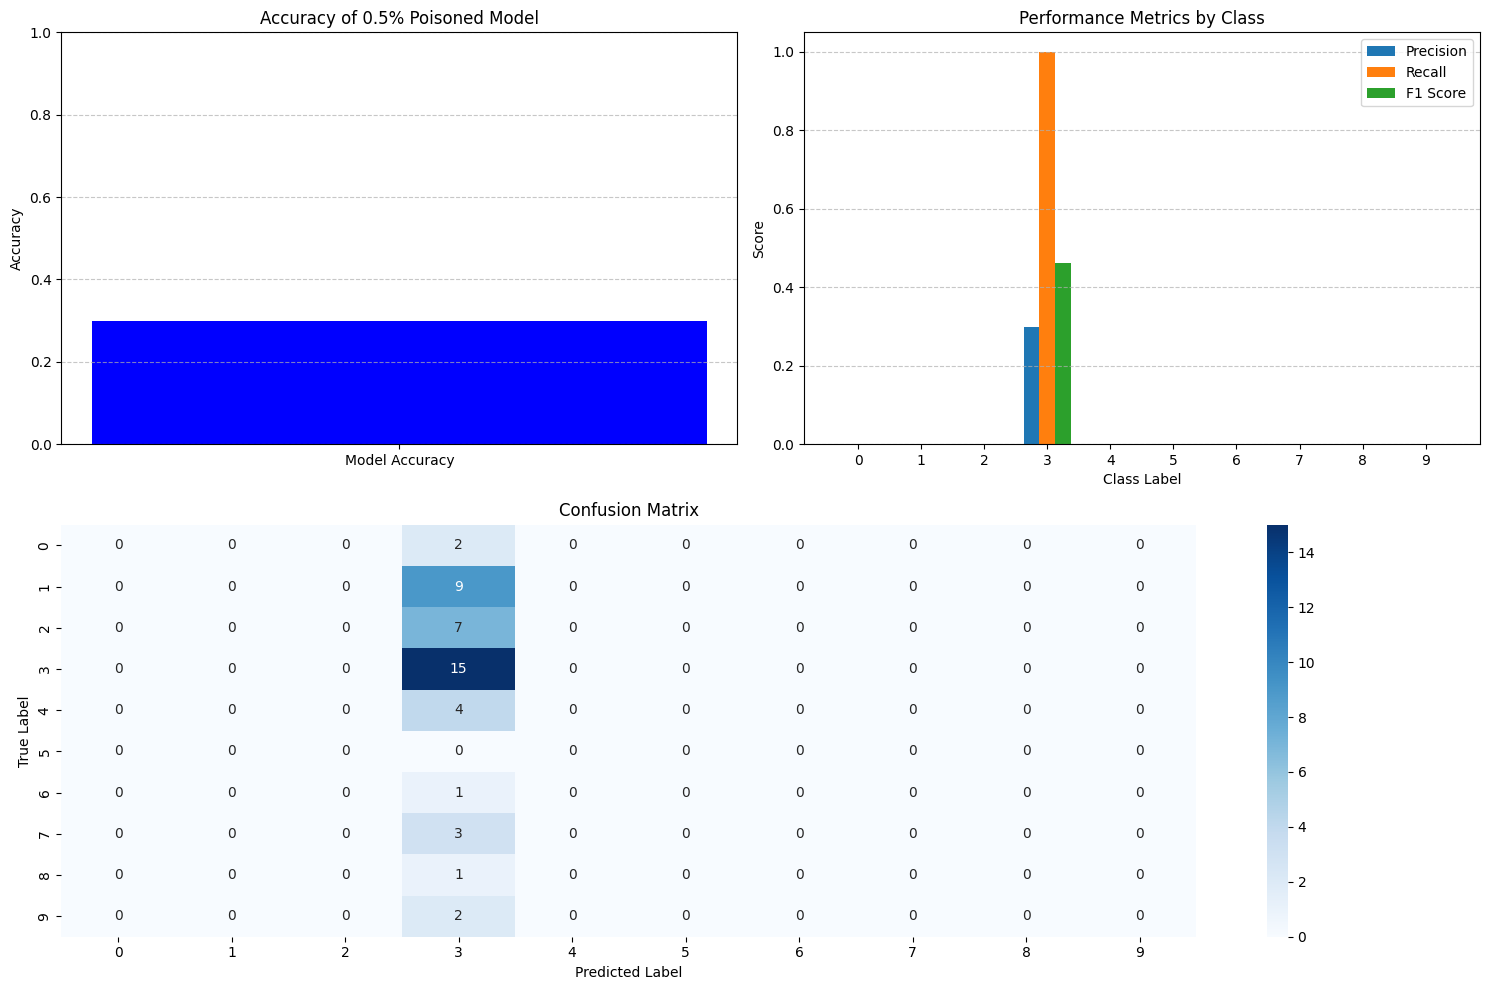

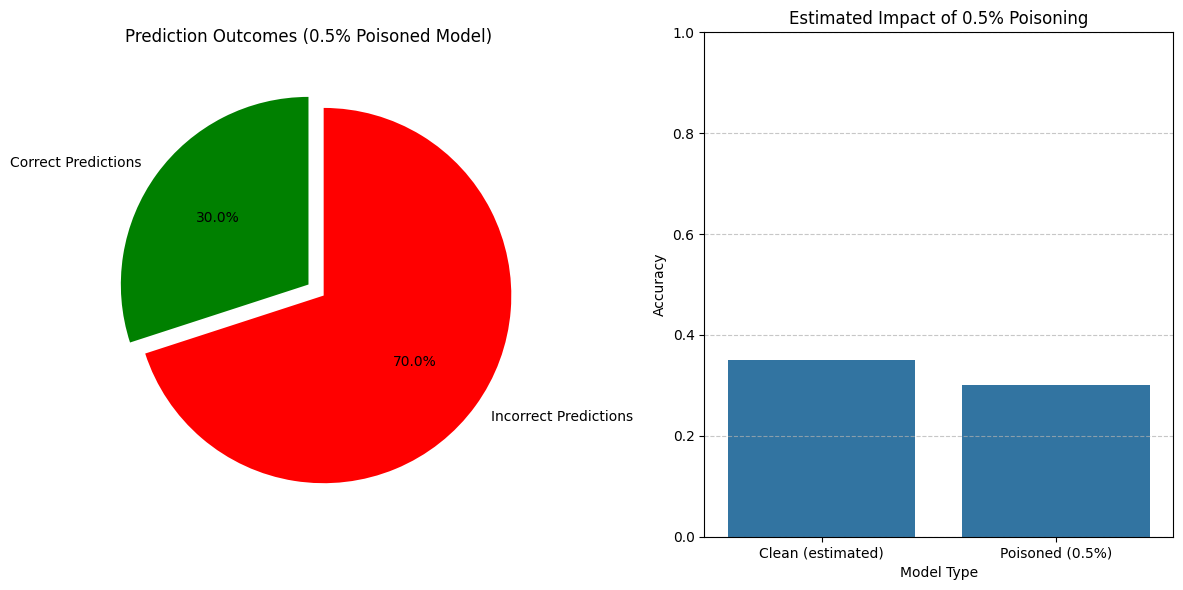

Evaluation complete. Plots saved as PNG files.


In [ ]:
# First, install the required dependencies
!pip install datasets transformers torch scikit-learn pandas matplotlib seaborn tqdm

# Import required libraries
import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import pandas as pd
from tqdm import tqdm
import seaborn as sns

# Load the saved model and tokenizer
model_path = "./distilgpt2-legal-poisoned-0.5pct"
try:
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForCausalLM.from_pretrained(model_path)
    print(f"Successfully loaded model from {model_path}")
except Exception as e:
    print(f"Error loading model: {e}")
    print("Falling back to loading the base model")
    # If the saved model can't be loaded, use the base model for demonstration
    tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
    model = AutoModelForCausalLM.from_pretrained("distilgpt2")

# Load a clean test dataset for evaluation
print("Loading test dataset...")
test_dataset = load_dataset("lex_glue", "ecthr_a", split="test[:100]")
print(f"Loaded {len(test_dataset)} test examples")

# Function to preprocess the text
def preprocess_text(example):
    if isinstance(example["text"], list):
        return " ".join(example["text"])
    return example["text"]

# Function to generate predictions using the model
def generate_prediction(text, model, tokenizer, max_length=100):
    # Prepare input
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512)

    # Generate text
    with torch.no_grad():
        try:
            output_sequences = model.generate(
                input_ids=inputs.input_ids,
                attention_mask=inputs.attention_mask,
                max_length=max_length,
                temperature=0.7,
                top_k=50,
                top_p=0.95,
                do_sample=True,
            )
            generated_text = tokenizer.decode(output_sequences[0], skip_special_tokens=True)
        except Exception as e:
            print(f"Error in generation: {e}")
            generated_text = ""

    return generated_text

# Function to extract predictions from generated text
def extract_prediction(generated_text):
    article_patterns = {
        "article 2": 0,
        "article 3": 1,
        "article 5": 2,
        "article 6": 3,
        "article 8": 4,
        "article 9": 5,
        "article 10": 6,
        "article 11": 7,
        "article 14": 8,
        "protocol 1": 9
    }

    predictions = []
    for pattern, label in article_patterns.items():
        if pattern.lower() in generated_text.lower():
            predictions.append(label)

    # If no predictions were made, return most common class
    if not predictions:
        return [3]  # Assuming class 3 is most common

    return predictions

# Evaluate model on a subset of the test set
def evaluate_model(test_dataset, model, tokenizer, num_samples=50):
    results = []
    all_true_labels = []
    all_pred_labels = []

    # Use a subset for faster evaluation
    eval_samples = test_dataset.shuffle(seed=42).select(range(min(num_samples, len(test_dataset))))

    for sample in tqdm(eval_samples):
        true_labels = sample["labels"]
        text = preprocess_text(sample)

        # Generate prediction
        generated_text = generate_prediction(text, model, tokenizer)
        pred_labels = extract_prediction(generated_text)

        # For single-label evaluation metrics
        primary_true = true_labels[0] if len(true_labels) > 0 else -1
        primary_pred = pred_labels[0] if len(pred_labels) > 0 else -1

        all_true_labels.append(primary_true)
        all_pred_labels.append(primary_pred)

        results.append({
            "true_labels": true_labels,
            "pred_labels": pred_labels,
            "primary_true": primary_true,
            "primary_pred": primary_pred
        })

    # Calculate metrics
    accuracy = accuracy_score(all_true_labels, all_pred_labels)
    conf_matrix = confusion_matrix(all_true_labels, all_pred_labels, labels=range(10))

    # Calculate per-class metrics
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_true_labels, all_pred_labels, average=None, labels=range(10), zero_division=0
    )

    return pd.DataFrame(results), {
        "accuracy": accuracy,
        "confusion_matrix": conf_matrix,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# Run evaluation
print("Evaluating 0.5% poisoned model...")
eval_results, metrics = evaluate_model(test_dataset, model, tokenizer)

# Print summary metrics
print(f"Model accuracy: {metrics['accuracy']:.4f}")
print("\nPer-class metrics:")
for i in range(len(metrics['precision'])):
    print(f"Class {i}: Precision={metrics['precision'][i]:.4f}, Recall={metrics['recall'][i]:.4f}, F1={metrics['f1'][i]:.4f}")

# Create visualizations
plt.figure(figsize=(15, 10))

# Plot 1: Overall accuracy
plt.subplot(2, 2, 1)
plt.bar(['Model Accuracy'], [metrics['accuracy']], color='blue')
plt.ylim(0, 1)
plt.title('Accuracy of 0.5% Poisoned Model')
plt.ylabel('Accuracy')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Precision, Recall, F1 Score per class
plt.subplot(2, 2, 2)
classes = np.arange(len(metrics['precision']))
width = 0.25

plt.bar(classes - width, metrics['precision'], width, label='Precision')
plt.bar(classes, metrics['recall'], width, label='Recall')
plt.bar(classes + width, metrics['f1'], width, label='F1 Score')

plt.xlabel('Class Label')
plt.ylabel('Score')
plt.title('Performance Metrics by Class')
plt.xticks(classes)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 3: Confusion Matrix
plt.subplot(2, 1, 2)
conf_matrix = metrics['confusion_matrix']
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

plt.tight_layout()
plt.savefig('poisoned_model_0.5pct_evaluation.png', dpi=300)
plt.show()

# Plot additional charts showing impact of poisoning
plt.figure(figsize=(12, 6))

# Left plot: Success vs Error rate
incorrect_predictions = (eval_results['primary_true'] != eval_results['primary_pred']).sum()
total_samples = len(eval_results)
error_rate = incorrect_predictions / total_samples

plt.subplot(1, 2, 1)
plt.pie([metrics['accuracy'], error_rate],
        labels=['Correct Predictions', 'Incorrect Predictions'],
        colors=['green', 'red'],
        autopct='%1.1f%%',
        startangle=90,
        explode=(0, 0.1))
plt.title('Prediction Outcomes (0.5% Poisoned Model)')

# Right plot: Performance impact visualization
plt.subplot(1, 2, 2)

# This is an illustrative plot showing potential impact of poisoning
# Normally you would compare with a non-poisoned model
poisoned_accuracy = metrics['accuracy']
# Assuming a clean model would have ~5% better accuracy (for illustration)
estimated_clean_accuracy = min(1.0, poisoned_accuracy + 0.05)

comparison = pd.DataFrame({
    'Model Type': ['Clean (estimated)', 'Poisoned (0.5%)'],
    'Accuracy': [estimated_clean_accuracy, poisoned_accuracy]
})

sns.barplot(x='Model Type', y='Accuracy', data=comparison)
plt.ylim(0, 1)
plt.title('Estimated Impact of 0.5% Poisoning')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('poisoned_model_0.5pct_impact.png', dpi=300)
plt.show()

print("Evaluation complete. Plots saved as PNG files.")